# What does a random-approval slice cost, and what does it buy?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/exploration-budget/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/exploration-budget/demo.ipynb)

`selective-labels` found that when past approvals used a signal nobody recorded, the labeled rows rank a worse credit
model first and only a random-approval slice ranks it right. Risk asks the next question: what does that slice cost
in bad loans, and what is the smallest one that still gets the ranking right? This notebook prices two designs.

1. The engine
2. What each design lends into
3. Cost and power, design by design
4. The cheapest slice that ranks right
5. What targeted cannot do: the fairness audit
6. The chart
7. Try your own

## 1. The engine

Extracted from `explore.py` at build time. The world is the one `selective-labels` declared. **Uniform** approves a
random share of all applicants. **Targeted** uses production's own approvals, labeled for free, and approves a
random share `q` of only the rows a challenger wants and production refused, weighting them 1/q. Every design point
is replayed 400 times on the same applicants. `study` runs the same three seeds as `evidence.py` (about 8 seconds),
so the numbers match `evidence.txt` exactly.

In [1]:
from __future__ import annotations

import warnings
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore", category=RuntimeWarning)

SEEDS = [200, 201, 202]


N = 40_000  # applicants per period


APPROVE = 0.40


REPS = 400  # replayed random slices per design point


UNIFORM = [0.0025, 0.005, 0.01, 0.02, 0.05, 0.10]  # share of all applicants approved at random


TARGETED = [0.01, 0.02, 0.05, 0.10, 0.20, 0.50]  # share of challenger-only rows approved at random


GAIN, LOSS = 300.0, 1_500.0  # declared: margin on a repaid loan, loss on a default (break-even repay 83.3%)


PER = 10_000  # costs reported per 10,000 applicants


Z = 1.96


WORLD: Dict[str, float] = {"share_b": 0.30, "sel_u": 1.0, "bar_b": 0.6, "officer_noise": 0.5, "noise": 0.8}


def draw(n: int, rng: np.random.Generator, w: Optional[Dict[str, float]] = None) -> Dict[str, np.ndarray]:
    """One period: applicants, true outcome, and production's decision (label observed iff approved)."""
    w = w or WORLD
    g = (rng.random(n) < w["share_b"]).astype(int)
    x = rng.normal(0, 1, n)
    u = rng.normal(0, 1, n)
    y = (0.8 * x + 0.8 * u + rng.normal(0, w["noise"], n) > -0.4).astype(int)  # 1 = repays
    s = x + w["sel_u"] * u - w["bar_b"] * g + rng.normal(0, w["officer_noise"], n)
    return {"x": x, "u": u, "g": g, "y": y, "prod": s >= np.quantile(s, 1 - APPROVE)}


def fit(d: Dict[str, np.ndarray], mask: Optional[np.ndarray] = None) -> HistGradientBoostingClassifier:
    m = np.ones(len(d["y"]), bool) if mask is None else mask
    return HistGradientBoostingClassifier(random_state=0).fit(np.column_stack([d["x"], d["g"]])[m], d["y"][m])


def decide(model: HistGradientBoostingClassifier, d: Dict[str, np.ndarray]) -> np.ndarray:
    p = model.predict_proba(np.column_stack([d["x"], d["g"]]))[:, 1]
    return p >= np.quantile(p, 1 - APPROVE)


def net(y: np.ndarray) -> np.ndarray:
    return np.where(y == 1, GAIN, -LOSS)


def uniform_est(y: np.ndarray, a: np.ndarray, sl: np.ndarray) -> np.ndarray:
    """Repay among the challenger's approvals, read on a random slice. sl: (reps, n) bool."""
    k = (sl & a).sum(1)
    return np.where(k > 0, (sl & a & (y == 1)).sum(1) / np.maximum(k, 1), np.nan)


def targeted_est(y: np.ndarray, a: np.ndarray, prod: np.ndarray, sl: np.ndarray, q: float) -> np.ndarray:
    """Overlap with production is fully labeled; challenger-only rows are sampled at q and weighted 1/q."""
    free = float((a & prod & (y == 1)).sum())
    sampled = (sl & a & ~prod & (y == 1)).sum(1) / q
    return (free + sampled) / a.sum()


def tpr_b(y: np.ndarray, a: np.ndarray, g: np.ndarray, wt: np.ndarray) -> np.ndarray:
    """Share of group B's good payers the challenger approves, from weighted labeled rows. wt: (reps, n)."""
    good = (y == 1) & (g == 1)
    return (wt * (good & a)).sum(1) / np.maximum((wt * good).sum(1), 1e-9)


def one_seed(seed: int, n: int = N, reps: int = REPS) -> Dict[str, object]:
    rng = np.random.default_rng(seed)
    train, ev = draw(n, rng), draw(n, rng)
    a_o, a_l = decide(fit(train), ev), decide(fit(train, train["prod"]), ev)
    y, g, prod = ev["y"], ev["g"], ev["prod"]
    truth = {"oracle": float(y[a_o].mean()), "label": float(y[a_l].mean())}
    good_b = (y == 1) & (g == 1)
    out: Dict[str, object] = {
        "truth": truth,
        "true_tpr_b": float(a_o[good_b].mean()),
        "rejected_repay": float(y[~prod].mean()),
        "challenger_only_repay": float(y[(a_o | a_l) & ~prod].mean()),
        "unreachable_good_b": float((good_b & ~(prod | a_o | a_l)).sum() / good_b.sum()),
        "agree": float((a_o & a_l).sum() / a_o.sum()),
    }
    r = np.random.default_rng(seed + 90_000)

    def summarise(
        eo: np.ndarray, el: np.ndarray, extra: np.ndarray, cost: float, tb: np.ndarray
    ) -> Dict[str, float]:
        d = eo - el
        return {
            "extra_loans": float(extra.mean()) * PER / n,
            "net_cost": cost * PER / n,
            "p_right": float(np.mean(d > 0)),
            "diff_ci": float(Z * np.nanstd(d)),
            "bias_oracle": float(np.nanmean(eo) - truth["oracle"]),
            "bias_label": float(np.nanmean(el) - truth["label"]),
            "tpr_b_bias": float(np.nanmean(tb) - out["true_tpr_b"]),
        }

    for e in UNIFORM:
        sl = r.random((reps, n)) < e
        extra = (sl & ~prod).sum(1)
        cost = -e * float(net(y[~prod]).sum())
        out[f"uniform_{e:g}"] = summarise(
            uniform_est(y, a_o, sl), uniform_est(y, a_l, sl), extra, cost, tpr_b(y, a_o, g, sl.astype(float))
        )
    pool = (a_o | a_l) & ~prod  # rows any challenger wants that production refused
    for q in TARGETED:
        sl = (r.random((reps, n)) < q) & pool
        wt = np.where(prod, 1.0, 0.0) + sl / q  # labeled weight: 1 for production rows, 1/q for sampled
        cost = -q * float(net(y[pool]).sum())
        out[f"targeted_{q:g}"] = summarise(
            targeted_est(y, a_o, prod, sl, q),
            targeted_est(y, a_l, prod, sl, q),
            sl.sum(1),
            cost,
            tpr_b(y, a_o, g, wt),
        )
    return out


def study(seeds: Optional[List[int]] = None, n: int = N, reps: int = REPS) -> Dict[str, object]:
    per = [one_seed(s, n, reps) for s in seeds or SEEDS]

    def tree(get) -> object:
        first = get(per[0])
        if isinstance(first, dict):
            return {k: tree(lambda p, k=k, get=get: get(p)[k]) for k in first}
        v = np.array([get(p) for p in per], float)
        return {"mean": float(v.mean()), "lo": float(v.min()), "hi": float(v.max())}

    return {"seeds": seeds or SEEDS, "n": n, "reps": reps, **tree(lambda p: p)}


def cheapest(r: Dict[str, object], design: str, target: float = 0.95) -> Optional[Dict[str, float]]:
    """Cheapest point of a design whose WORST seed still ranks the models right at `target` probability."""
    grid = UNIFORM if design == "uniform" else TARGETED
    for s in grid:
        p = r[f"{design}_{s:g}"]
        if p["p_right"]["lo"] >= target:
            return {"share": s, "net_cost": p["net_cost"]["mean"], "extra_loans": p["extra_loans"]["mean"]}
    return None

In [2]:
r = study()
pct = lambda v: f"{v['mean']:.1%} [{v['lo']:.1%}-{v['hi']:.1%}]"
usd = lambda v: f"${v:,.0f}"
print(f"study done: {len(r['seeds'])} seeds, {r['n']:,} applicants per period, {r['reps']} replays per point")

study done: 3 seeds, 40,000 applicants per period, 400 replays per point


## 2. What each design lends into

The rows production refused repay 41.3%; uniform explore lends into all of them. The rows a challenger wants and
production refused repay 54.3%; that band is all targeted ever lends into. At a $300 margin and $1,500 loss both lose
money per loan, but targeted loses less per loan and needs fewer of them, because the 74% of approvals the two
challengers share with each other are mostly already labeled.

In [3]:
print(f"true repay among approvals: oracle {pct(r['truth']['oracle'])}, label-trained {pct(r['truth']['label'])}")
print(f"repay rate of rows production refused (uniform's extra loans): {pct(r['rejected_repay'])}")
print(f"repay rate of rows a challenger wants and production refused (targeted's pool): {pct(r['challenger_only_repay'])}")
print(f"oracle approvals the label-trained model also approves: {pct(r['agree'])}")

true repay among approvals: oracle 82.8% [82.6%-83.0%], label-trained 76.4% [73.1%-78.6%]
repay rate of rows production refused (uniform's extra loans): 41.3% [41.1%-41.5%]
repay rate of rows a challenger wants and production refused (targeted's pool): 54.3% [50.1%-56.4%]
oracle approvals the label-trained model also approves: 74.4% [70.6%-77.1%]


## 3. Cost and power, design by design

`P right` is the share of replayed slices in which the oracle (truly 6.4 points better) comes out ahead. Both designs
are unbiased (bias column, about zero); they differ in what each point costs. At about the same spend, uniform 0.5%
($22,702) ranks right 90.6% of the time with a +/-8.0 point interval on the gap; targeted 2% ($23,280) ranks right
99.5% of the time at +/-4.1.

In [4]:
print(f"{'design':<16} {'extra loans':>12} {'net cost':>10} {'P right (worst seed)':>22} {'95% CI on gap':>15} {'bias oracle':>12}")
for design, grid in (("uniform", UNIFORM), ("targeted", TARGETED)):
    for s in grid:
        p = r[f"{design}_{s:g}"]
        print(f"{design + ' ' + format(s, '.2%'):<16} {p['extra_loans']['mean']:>12,.0f} {usd(p['net_cost']['mean']):>10} "
              f"{p['p_right']['mean']:>12.1%} ({p['p_right']['lo']:.1%}) {'+/-' + format(p['diff_ci']['mean'] * 100, '.1f') + ' pts':>15} "
              f"{p['bias_oracle']['mean'] * 100:>+10.2f} pts")

design            extra loans   net cost   P right (worst seed)   95% CI on gap  bias oracle
uniform 0.25%              15    $11,351        85.2% (77.0%)     +/-11.5 pts      +0.34 pts
uniform 0.50%              30    $22,702        90.6% (82.0%)      +/-8.0 pts      +0.12 pts
uniform 1.00%              60    $45,405        96.9% (92.2%)      +/-5.4 pts      +0.04 pts
uniform 2.00%             120    $90,810        99.5% (98.8%)      +/-4.0 pts      -0.06 pts
uniform 5.00%             300   $227,025       100.0% (100.0%)      +/-2.4 pts      +0.00 pts
uniform 10.00%            600   $454,050       100.0% (100.0%)      +/-1.6 pts      +0.02 pts
targeted 1.00%             22    $11,640        95.5% (91.8%)      +/-6.0 pts      -0.03 pts
targeted 2.00%             44    $23,280        99.5% (98.8%)      +/-4.1 pts      +0.02 pts
targeted 5.00%            111    $58,199       100.0% (100.0%)      +/-2.7 pts      -0.04 pts
targeted 10.00%           221   $116,398       100.0% (100.0%)     

## 4. The cheapest slice that ranks right

Asking for 95% at the worst of three seeds: uniform needs 2% ($90,810 per 10,000 applicants); targeted needs 2%
($23,280), 3.9x cheaper. Both are far below `selective-labels`' 5% ($227,025): that number was sized for a +/-2.6
point interval on one model's repay level. Ranking two models is a paired question, and the shared approvals cancel.

In [5]:
for design in ("uniform", "targeted"):
    b = cheapest(r, design)
    print(f"{design:<9} {b['share']:.2%} slice: {b['extra_loans']:,.0f} extra loans, net cost {usd(b['net_cost'])}")
print(f"targeted is {cheapest(r, 'uniform')['net_cost'] / cheapest(r, 'targeted')['net_cost']:.1f}x cheaper for the same verdict")
u, t = r["uniform_0.005"], r["targeted_0.02"]
print(f"at about the same spend: uniform 0.50% {usd(u['net_cost']['mean'])} -> P {u['p_right']['mean']:.1%}, CI +/-{u['diff_ci']['mean'] * 100:.1f}; "
      f"targeted 2.00% {usd(t['net_cost']['mean'])} -> P {t['p_right']['mean']:.1%}, CI +/-{t['diff_ci']['mean'] * 100:.1f}")

uniform   2.00% slice: 120 extra loans, net cost $90,810
targeted  2.00% slice: 44 extra loans, net cost $23,280
targeted is 3.9x cheaper for the same verdict
at about the same spend: uniform 0.50% $22,702 -> P 90.6%, CI +/-8.0; targeted 2.00% $23,280 -> P 99.5%, CI +/-4.1


## 5. What targeted cannot do: the fairness audit

A true positive rate counts every good payer, including the ones that neither production nor any challenger would
approve. 15.2% of group B's good payers sit there, and targeted never lends to them. Its estimate of the oracle's
TPR for B is +9.5 points too high at 5%, and +9.6 at 50%: ten times the spend, the same bias. Uniform 5% is off by
-0.1. Use targeted to choose between models; keep a small uniform slice for the audit.

In [6]:
print(f"true TPR B {pct(r['true_tpr_b'])}; B good payers no design but uniform can ever label: {pct(r['unreachable_good_b'])}")
for design, s in (("uniform", 0.05), ("targeted", 0.05), ("targeted", 0.5)):
    p = r[f"{design}_{s:g}"]
    print(f"  {design} {s:.0%}: TPR B bias {p['tpr_b_bias']['mean'] * 100:+.1f} pts [{p['tpr_b_bias']['lo'] * 100:+.1f} to {p['tpr_b_bias']['hi'] * 100:+.1f}]")

true TPR B 53.2% [52.1%-54.3%]; B good payers no design but uniform can ever label: 15.2% [13.1%-17.6%]
  uniform 5%: TPR B bias -0.1 pts [-0.2 to -0.1]
  targeted 5%: TPR B bias +9.5 pts [+8.1 to +11.2]
  targeted 50%: TPR B bias +9.6 pts [+8.2 to +11.3]


## 6. The chart

The full figure, with the who-lends-to-whom strip drawn, is `audit.png` (built by `make_chart.py`). Here, cost
against power.

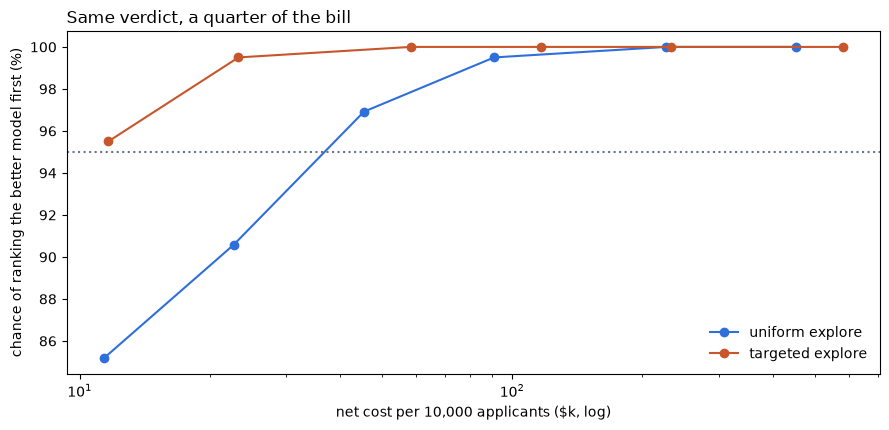

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for design, grid, col in (("uniform", UNIFORM, "#2f6fdb"), ("targeted", TARGETED, "#c8562b")):
    ax.plot([r[f"{design}_{s:g}"]["net_cost"]["mean"] / 1000 for s in grid],
            [r[f"{design}_{s:g}"]["p_right"]["mean"] * 100 for s in grid], "o-", color=col, label=f"{design} explore")
ax.axhline(95, color="#6b7684", ls=":")
ax.set_xscale("log")
ax.set_xlabel(f"net cost per {PER:,} applicants ($k, log)")
ax.set_ylabel("chance of ranking the better model first (%)")
ax.set_title("Same verdict, a quarter of the bill", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Choosing between two models is a paired question: a 2% uniform slice ranks them right where Day 200 sized 5% for
  a level estimate.
- Production's approvals are already labeled. Sampling only the rows a challenger wants and production refused gives
  the same verdict for about a quarter of the loss.
- That cheap design cannot audit fairness: good payers nobody would approve are never labeled, and no amount of
  targeted spend reaches them.

## 7. Try your own

In [8]:
# A harsher loss: rerun one seed and compare the cheapest designs' costs.
# GAIN, LOSS = 300.0, 4_000.0
# x = study([200], n=20_000, reps=200); print(cheapest(x, "uniform"), cheapest(x, "targeted"))

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version takes your own
loan economics: `pip install -r requirements.txt && streamlit run app.py`.

Sibling build: [`selective-labels`](../selective-labels) found the problem this build prices.